In this notebook, I will be making use of the Kaggle dataset conducted by a fictional e-commerce company, Shopster. This A/B Testing analysis is done in companion with resources from github and kaggle, as well as making use of youtube and google resources for better understanding. 


Through this realistic case study, we will explore from beginning to end of the A/B testing lifecycle:

1. Understanding of problem
2. Defining our hypothesis
3. Designing our experiment
4. Running the experiment
5. Validity checks
6. Analysing the results
7. Justifying launch decisions

---

Dataset

This dataset contains information on 20000 customers, who were subject to A/B testing for 31 days.

The columns in this dataset includes:
`customerID`: customer identifier
`test group`: subjecting customers into psa and ad groups
`made_purchase`: whether a user completed a purchase (binary)
`ad_count`: number of ads seen
`peak ad hours`: hours with highest ad exposure
`days_with_most_ads`: day with the most ad impressions

We will be making use of this dataset to walk through the entire A/B testing lifecycle, ultimately presenting our final business recommendations based on our testing.

---

1. Understanding of problem

The dataset is trying to explore whether a large company with a substantial user base plans to increase sales through advertisement on its website. The customers are tested through being segmented into 2 groups, `psa` and `ad`. 

Objective:

Through this test, the objective is to find out whether a redesigned ad format can increase the likelihood of customer purchases compared to traditional commercial versions. 

Looking at the user funnel, this intervention is targetting the purchase stage of the user funnel. Users were randomnly assigned to the control group (`psa`) and treatment group (`ad` ) group over a 31 day period.


Primary Metric

- *Conversion Rate*: percentage of users who completed a purchase (`made_purchase = True`)

Secondary Metric

- **Ad exposure volume**: number of ads seen per person
- **Peak Ad Hour**: Hours of highest ad exposure
- **Day of Peak Exposure**: Day of the month with most impressions

---

2. Define Hypothesis and parameters

Next, we will define the statistical framework of our experiment. We will be setting the parameters, formulatting the hypothesis and test type, in order to solidify our statistical thresholds and guide our inference of results.

Statistical parameters:

a. **Significance Level**: 0.05
b. **Statistical Power**: 0.80
This represents the probabilty of correctlty rejecting the null hypothesis when the alternative is true. A power of 80% reflects a common trade off between sensitivity and required sample size.
c. **Minimum Detectable Effect (MDE): 15%
This is the smallest relative change in the conversion rate that we consider practically meaningful from a business standpoint

Hypothesis Formulation:

**Null Hypothesis:** The conversion rate of the treatment group is less than or equal to 15% higher than that of the control group

**Alternative Hypothesis:** The conversion rate of the treatment group is more than 15% higher than the control group

Since we aim to detect whether the treatment leads to a conversion rate that is at least 15% higher than the control, we’ll conduct a one-sided test. 

In the next step, we’ll design the experiment.

---

3. Designing the experiment

In our dataset, each row represents a user that has been exposed to either the `psa` or the `ad` format. Hence, we assume that users were randomly assigned to either the control (`psa`) group or the treatment (`ad`) group at the beginning of the experiment

We will make use of the design parameters that we have chosen from the previous section (section 2):

**Primary Metric:** `made_purchase` used to identify Conversion Rate
**Secondary Metric:** `ad_count`: number of adds seen per user, `peak_ad_hours`: hour of hieghest ad exposure, `days_with_most_ads`: day of the month with the most impressions
**Significance Level:** 0.05
**Statistical Power:** 0.80
**Minimum Detectable Effect:** 15% relative increase in conversion
**Test Type:** One sided test

While many A/B tests make use of a 50/50 split, this experiment was designed with the intentional 60/40 allocation in favour of the treatment group. This allows for faster learning of the new ad's format and performance while still maintaining sufficient statistical power in the control group (40%).


What we know from historical data
Based on prior control group performance, the observed conversion rate `made_purchase` is:
- p_control = 0.0666, i.e 6.66% of people were converted
- variance: 0.0622, (p x (1-p)), where p is the probability of making a purchase and 1-p is the probability of not making a purchase


As we assume that the variance remains approximately equal across both control and treatment groups, we apply this value as the pooled variance in the sample size formula. 

With the MDE as 15%, the expected improvement threshold is:

**Δ = p_control × MDE = 0.0666 × 0.15 ≈ 0.00999** (about 1%)

henche yielding the below for the formula:

- σ² = 0.0622
- Δ² ≈ 0.0000998

Next, we want to determine how many people we need in our sample size in our control and treatment group for us to detect an improvement in conversion rate. 

For a one-sided test, we use the following formula:
$$
n \approx \frac{(Z_{1-\alpha} + Z_{1-\beta})^2 \cdot 2 \cdot \sigma^2}{\Delta^2}
$$

For a one-sided test at α = 0.05 and power = 0.80, we use:

Z₁₋α = 1.64
Z₁₋β = 0.84

$$
n \approx \frac{16 \cdot \sigma^2}{\Delta^2}
$$


---

4. Running the experiment

Key considerations include:

a. Random assignment: Users must be randomly assigned to the control or treatment group, and can only belong to one group

b. Consistent Exposure: Once the experiment begins, the logic in which ad is shown, formats, etc. should remain unchanged. 

c. Metric Instrumentation: All outcomes must be carefully logged in the way that they are presented to allow unbiased reporting

d. Avoiding peeking: Interim checks on results should be avoided to prevent bias points of views before the experiment has concluded

---

5. Validity checks

We need to perform data quality checks to ensure that the experiment was conducted under valid conditions. This can be in terms of 

- **Sample Ratio Mismatch:** Check whether the actual group allocation reflects the intended experimental desgin. A significant deviation in group sizes can indicate randomisation failure or data loss

- **Duration:** Ensuring that the experiment runs in a sufficient and stable timeline, with accounts for weekday effects, seasonality, potential novelty or maturation effects. 

- **Instrumentation Integrity:** Verify that all key variables are carefully populated and not missing values that can impede the experiment

- **Baseline Symmetry:** Compare pre-treatment characteristics (such as ad exposure volume or exposure timing) to confirm that groups were similar before any effect of the treatment could manifest.

- **Regression to the Mean:** Evaluate whether extreme baseline behaviors (e.g., high or low ad exposure) normalize across groups and time, potentially distorting the observed impact of the treatment.


As our dataset has been finalised, we will assume that the above points have been taken care of. 

Next, we will perform the statistical validation checks:


In [21]:
import pandas as pd
from scipy.stats import chisquare 
import kagglehub #allows me to download and access kaggle datasets from python
import os

path = kagglehub.dataset_download(
    "farhadzeynalli/online-advertising-effectiveness-study-ab-testing"
)
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "online_ad_AB.csv"))

df.head()

['online_ad_AB.csv']


,customerID,test group,made_purchase,days_with_most_add,peak ad hours,ad_count
0,1,ad,False,24,20,5
1,2,psa,False,21,16,9
2,3,psa,False,1,18,8
3,4,ad,False,20,23,7
4,5,ad,False,3,13,5


Checking the column headings, we will replace the `days_with_most_add` to `days_with_most_ads`

In [22]:
df.rename(columns={'days_with_most_add': 'days_with_most_ads'}, inplace=True)
df.head()

,customerID,test group,made_purchase,days_with_most_ads,peak ad hours,ad_count
0,1,ad,False,24,20,5
1,2,psa,False,21,16,9
2,3,psa,False,1,18,8
3,4,ad,False,20,23,7
4,5,ad,False,3,13,5


In [23]:
# Check for missing values
missing_values = df.isnull().sum()

# Check data types
dtypes = df.dtypes

# Display results in a clean summary table
quality_check = pd.DataFrame({
    'Missing Values': missing_values,
    'Data Type': dtypes
})

display(quality_check)

,Missing Values,Data Type
customerID,0,int64
test group,0,object
made_purchase,0,bool
days_with_most_ads,0,int64
peak ad hours,0,int64
ad_count,0,int64


Next, we perform the relevant validity checks

Sample Mismatch


In [24]:
# Count users per group
group_counts = df['test group'].value_counts()
observed = group_counts.values

# Define expected proportions: 60% psa, 40% ad
expected_total = observed.sum()
expected = [expected_total * 0.6, expected_total * 0.4]

# Perform Chi-square test to detect Sample Ratio Mismatch (SRM)
chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

group_counts.to_dict(), expected, chi2_stat, p_value

print("Observed counts:", group_counts.to_dict())
print("Expected counts:", expected)
print("Chi-square statistic:", chi2_stat)
print("p-value:", p_value)

Observed counts: {'ad': 12053, 'psa': 7947}
Expected counts: [12000.0, 8000.0]
Chi-square statistic: 0.5852083333333333
p-value: 0.44427803130186905


Pre Treatment Symmetry

This is essential to ensure that groups are balanced in their pre-treatment characteristics.



In [25]:
# Compare pre-treatment variables between groups
grouped_summary = df.groupby('test group')[['ad_count', 'peak ad hours', 'days_with_most_ads']].agg(['mean', 'std'])

grouped_summary

ad_count           peak ad hours           days_with_most_ads  \
                mean       std          mean       std               mean   
test group                                                                  
ad          6.381067  2.554334     15.821870  6.229011          15.593960   
psa         6.408959  2.534506     15.964263  6.187886          15.448849   

                      
                 std  
test group            
ad          8.635782  
psa         8.690007

The differences is mean and standard deviation is minimal and not suggestive of imbalance. To statistically confirm that there are no baseline imbalances, we performed independent t-tests comparing the control (psa) and treatment (ad) groups across the following variables:


In [26]:
from scipy.stats import ttest_ind

# Split groups
control = df[df['test group'] == 'psa']
treatment = df[df['test group'] == 'ad']

# Run Welch's t-tests (no equal variance assumption)
results = {
    'Variable': ['ad_count', 'peak ad hours', 'days_with_most_ads'],
    't-statistic': [],
    'p-value': []
}

for var in results['Variable']:
    stat, p = ttest_ind(control[var], treatment[var], equal_var=False)
    results['t-statistic'].append(round(stat, 4))
    results['p-value'].append(f"{p:.4e}" if p < 0.001 else round(p, 4))

# Display as DataFrame
import pandas as pd
ttest_df = pd.DataFrame(results)
display(ttest_df)

,Variable,t-statistic,p-value
0,ad_count,0.7592,0.4477
1,peak ad hours,1.5883,0.1122
2,days_with_most_ads,-1.1585,0.2467


All p-values are well above the conventional threshold of 0.05, indicating no statistically significant differences between groups for these pre-treatment variables.


---

6. Analysing the results

With the validity checks completed and the data deemed suitable for analysis, we now proceed to evaluate the impact of the treatment on the primary and secondary metrics.

Objectives of This Step
This phase focuses on measuring whether the treatment group (ad) shows a statistically and practically meaningful difference compared to the control group (psa) in the following outcomes:

Primary metric: Conversion rate (made_purchase)
Secondary metrics:
Ad exposure volume (ad_count)
Temporal behavior:
Hour of peak exposure (peak ad hours)
Day of peak exposure (days_with_most_ads)
We aim to answer the following questions:

Is there a significant difference in conversion rate between the two groups?
How do conversion rates vary by day of the month and hour of the day across groups?
Are there consistent patterns when aggregating by day of the week (e.g., weekday vs. weekend)?
Do the distributions of secondary metrics differ between the control and treatment groups?


Approach
We will perform the following:

Global comparison of conversion rates between groups using statistical tests and confidence intervals.
Temporal visualizations:
Line plots of daily conversion rate by group across the 31 days.
Aggregated line plots by day of the week to assess behavioral cycles (e.g., weekdays vs. weekends).
Conversion rate by hour of the day.
Distributional analysis using boxplots:
Compare the spread of ad_count, peak ad hours, and days_with_most_ads across groups.
Identify any patterns or shifts in exposure dynamics caused by the new ad format.
These steps will provide both statistical evidence and behavioral insight into the impact of the ad format change.





In [27]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np
import pandas as pd

# Conversion counts and total users per group
conversions = df.groupby('test group')['made_purchase'].sum()
totals = df['test group'].value_counts()

# Conversion rates
p_control = conversions['psa'] / totals['psa']
p_treatment = conversions['ad'] / totals['ad']

# Absolute and relative differences
abs_diff = p_treatment - p_control
rel_diff = abs_diff / p_control

# Standard error and CI (absolute)
se_abs = np.sqrt(
    (p_control * (1 - p_control) / totals['psa']) +
    (p_treatment * (1 - p_treatment) / totals['ad'])
)
z = 1.96  # 95% CI
ci_lower_abs = abs_diff - z * se_abs
ci_upper_abs = abs_diff + z * se_abs

# CI for relative difference (approx via delta method)
se_rel = se_abs / p_control
ci_lower_rel = rel_diff - z * se_rel
ci_upper_rel = rel_diff + z * se_rel

# Perform one-sided Z-test
z_stat, p_val = proportions_ztest(count=conversions.values,
                                   nobs=totals.values,
                                   alternative='larger')

# Assemble result table
summary_table = pd.DataFrame({
    'Group': ['Control (psa)', 'Treatment (ad)'],
    'Conversion Rate': [f"{p_control:.2%}", f"{p_treatment:.2%}"],
    'Absolute Difference': ['', f"{abs_diff:.2%}"],
    'Relative Uplift': ['', f"{rel_diff:.2%}"],
    'P-Value': ['', f"{p_val:.4e}" if p_val < 0.001 else f"{p_val:.4f}"],
    '95% CI (Relative)': ['', f"({ci_lower_rel:.2%}, {ci_upper_rel:.2%})"]
})

display(summary_table)

if ci_lower_rel > 0.15:
    print("✅ The observed uplift exceeds the 15% MDE and is statistically significant.")
elif p_val < 0.05:
    print("⚠️ Statistically significant, but does not exceed the 15% MDE threshold.")
else:
    print("❌ No statistically or practically significant difference found.")

,Group,Conversion Rate,Absolute Difference,Relative Uplift,P-Value,95% CI (Relative)
0,Control (psa),3.23%,,,,
1,Treatment (ad),6.66%,3.43%,106.01%,1.6553e-26,"(87.73%, 124.29%)"


✅ The observed uplift exceeds the 15% MDE and is statistically significant.


Conclusion: The observed uplift in conversion rate is 106.01%, far exceeding the 15% threshold defined in the hypothesis. The 95% confidence interval for the relative difference is (87.73%, 124.29%), which does not include or overlap with the null threshold. Therefore, we reject the null hypothesis and conclude that the ad format resulted in a statistically and practically significant improvement in conversion rate compared to the control.
---

Temporal Analysis – Daily and Cumulative Conversion Rates

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Version

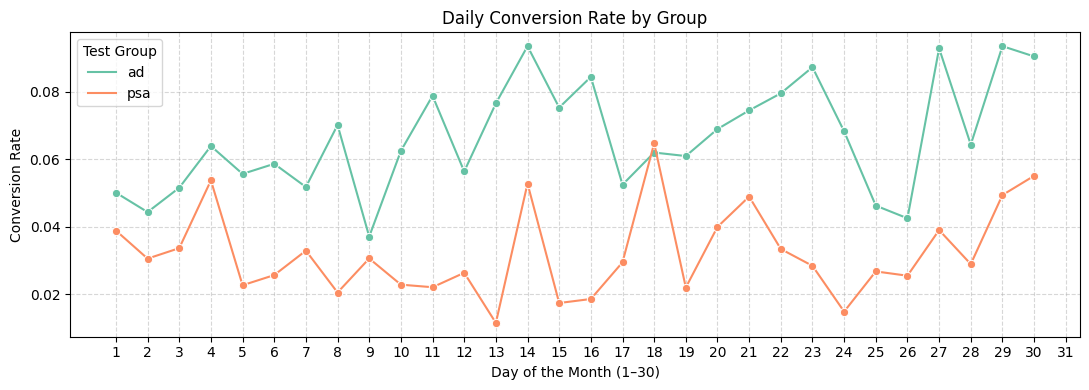

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use proxy for day of observation
df['day'] = df['days_with_most_ads']

# Compute daily conversion rate by group
daily_cr = (
    df.groupby(['day', 'test group'])['made_purchase']
    .mean()
    .reset_index()
)

# Plot daily conversion rate
plt.figure(figsize=(11, 4))
sns.lineplot(data=daily_cr,
             x='day',
             y='made_purchase',
             hue='test group',
             marker='o',
             palette='Set2')

plt.title('Daily Conversion Rate by Group')
plt.xlabel('Day of the Month (1–30)')
plt.ylabel('Conversion Rate')
plt.xticks(ticks=range(1, 32))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Test Group')
plt.tight_layout()
plt.show()

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Version

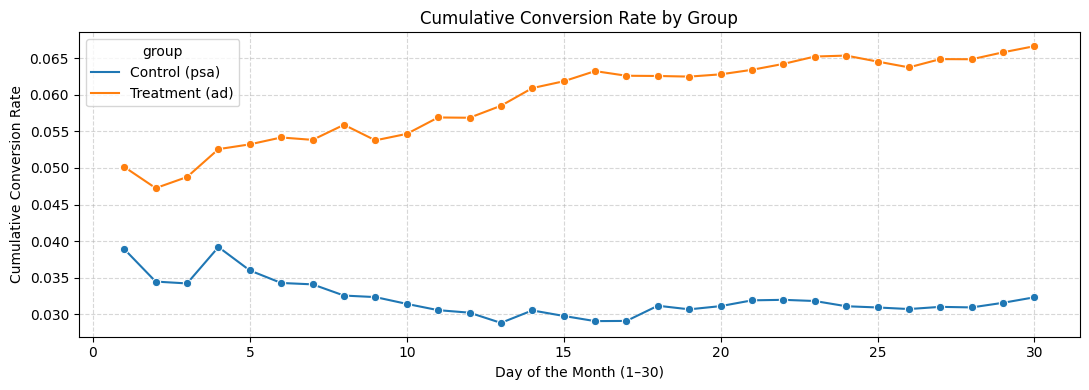

In [29]:
# Sort dataset by day
df_sorted = df.sort_values('day')
df_sorted['converted'] = df_sorted['made_purchase'].astype(int)
df_sorted['group'] = df_sorted['test group'].map({'ad': 'Treatment (ad)', 'psa': 'Control (psa)'})
df_sorted['user'] = 1

# Cumulative conversions and users per day and group
cumulative = (
    df_sorted.groupby(['day', 'group'])[['converted', 'user']]
    .sum()
    .groupby(level=1)
    .cumsum()
    .reset_index()
)

cumulative['cumulative_cr'] = cumulative['converted'] / cumulative['user']

# Plot cumulative conversion rate
plt.figure(figsize=(11, 4))
sns.lineplot(data=cumulative,
             x='day',
             y='cumulative_cr',
             hue='group',
             marker='o')

plt.title('Cumulative Conversion Rate by Group')
plt.xlabel('Day of the Month (1–30)')
plt.ylabel('Cumulative Conversion Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Two complementary visualizations were used to assess group performance over time:

Daily Conversion Rate:

The treatment group (ad) consistently achieved higher conversion rates across nearly all days.
The control group (psa) exhibited a flatter and consistently lower profile.
These patterns suggest that the observed effect is not driven by daily outliers but reflects a persistent performance gap.
Cumulative Conversion Rate:

The treatment group's cumulative curve rises more steeply, indicating a sustained advantage.
The divergence between groups increases over time, reinforcing the consistency of the treatment effect.
The control group accumulates conversions at a slower pace and never closes the gap.
✅ Conclusion: Temporal trends confirm that the higher conversion rate observed in the treatment group is consistent, stable, and not attributable to short-term variation. These findings support the robustness and durability of the treatment effect across the full 31-day experiment.

---

Conversion Rate by Hour



/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Version

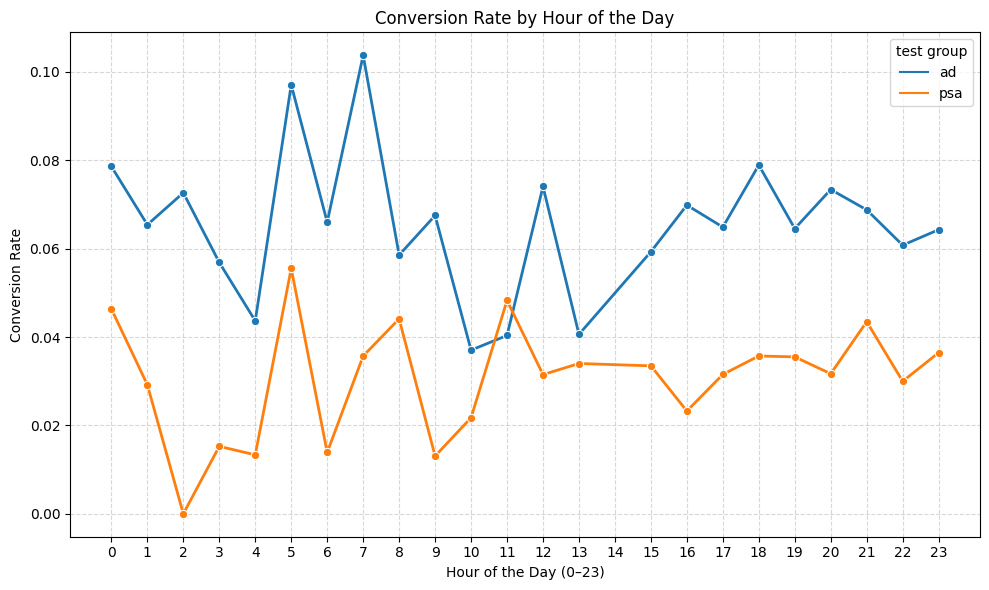

In [30]:
# Calcular tasa de conversión promedio por hora del día y grupo
hourly_cr = (
    df.groupby(['peak ad hours', 'test group'])['made_purchase']
    .mean()
    .reset_index()
)


plt.figure(figsize=(10, 6))
sns.lineplot(
    data=hourly_cr,
    x='peak ad hours',
    y='made_purchase',
    hue='test group',
    linewidth=2,
    marker='o',
    errorbar=None  # Removes shaded confidence intervals
)
plt.title('Conversion Rate by Hour of the Day')
plt.xlabel('Hour of the Day (0–23)')
plt.ylabel('Conversion Rate')
plt.xticks(ticks=range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The first chart shows the conversion rate by hour of the day for both the control group (psa) and the treatment group (ad).

Key observations:

Both groups follow a similar hourly pattern, with matching peaks and valleys. For example, both experience lower performance during nighttime hours and show clear spikes during early morning hours, including some unexpected peaks around 05:00–07:00.
However, the treatment group consistently outperforms the control group across almost all hours, maintaining a higher conversion rate at each time point.
The only notable exception occurs at hour 11, where the control group temporarily surpasses the treatment group.
These findings suggest that the treatment is not only more effective overall, but its advantage is preserved throughout the day, aligning closely with user activity patterns.

To improve interpretability and highlight time-of-day dynamics more intuitively, we segmented the 24-hour period into functional time blocks—such as sleeping hours, work hours, and evening hours—and re-plotted the conversion rate of the treatment group with these regions visually separated.

In [31]:
# Filter treatment group
df_ad = df[df['test group'] == 'ad'].copy()

# Ensure conversion is integer
df_ad['conversion'] = df_ad['made_purchase'].astype(int)

# Define time blocks
def categorize_hour(hour):
    if 0 <= hour < 5:
        return 'Sleeping Hours (00–04)'
    elif 5 <= hour < 8.5:
        return 'Wake-Up Hours (05–08)'
    elif 8.5 <= hour < 10.75:
        return 'Pre-lunch Work (08:30–10:45)'
    elif 10.75 <= hour < 12.5:
        return 'Lunch Break (11–12:30)'
    elif 12.5 <= hour < 17:
        return 'Post-lunch Work (12:30–17)'
    else:
        return 'Evening (17–23)'

# Apply block classification
df_ad['hour_block'] = df_ad['peak ad hours'].apply(categorize_hour)

# Order categories
hour_block_order = [
    'Sleeping Hours (00–04)',
    'Wake-Up Hours (05–08)',
    'Pre-lunch Work (08:30–10:45)',
    'Lunch Break (11–12:30)',
    'Post-lunch Work (12:30–17)',
    'Evening (17–23)'
]
df_ad['hour_block'] = pd.Categorical(df_ad['hour_block'], categories=hour_block_order, ordered=True)

# Compute summary statistics
summary_stats = (
    df_ad.groupby('hour_block')['conversion']
    .agg(['mean', 'std', 'count'])
    .rename(columns={'mean': 'conversion_rate', 'std': 'std_dev'})
    .reset_index()
)
summary_stats['se'] = summary_stats['std_dev'] / summary_stats['count']**0.5

/var/folders/0s/pxx_7k9n2572ygwnhl21g6nw0000gn/T/ipykernel_79658/738410220.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_ad.groupby('hour_block')['conversion']


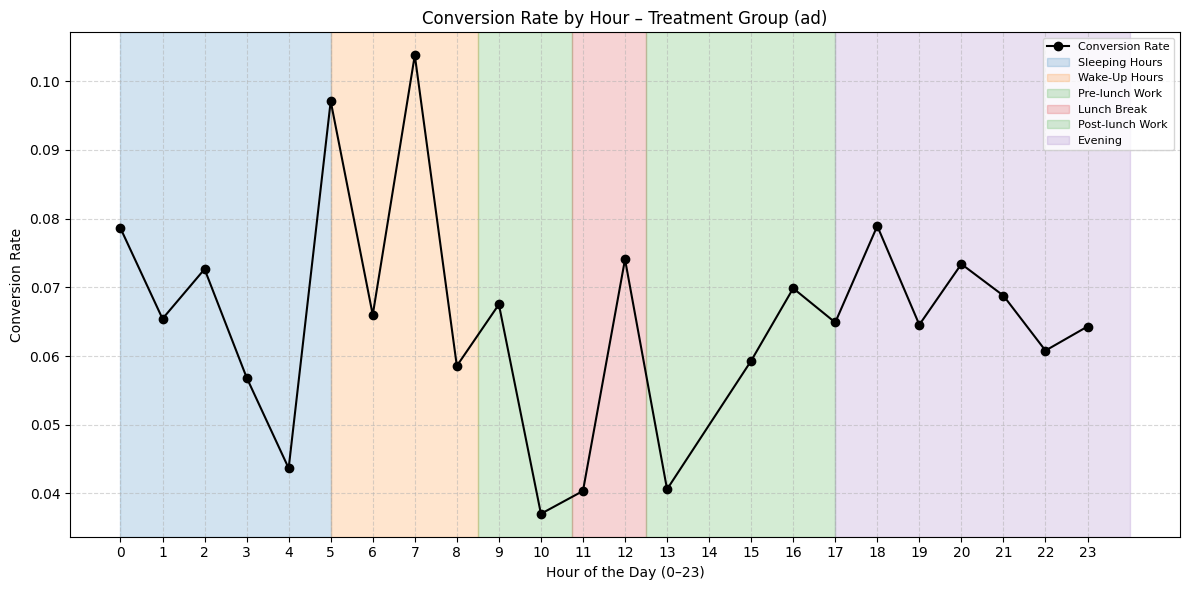

In [32]:
# Plot conversion rate by hour with shaded time zones
hourly_cr = (
    df_ad.groupby('peak ad hours')['conversion']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))
plt.plot(hourly_cr['peak ad hours'], hourly_cr['conversion'], marker='o', color='black', label='Conversion Rate')

# Highlight time blocks (manual overlay)
plt.axvspan(0, 5, color='#1f77b4', alpha=0.2, label='Sleeping Hours')
plt.axvspan(5, 8.5, color='#ff7f0e', alpha=0.2, label='Wake-Up Hours')
plt.axvspan(8.5, 10.75, color='#2ca02c', alpha=0.2, label='Pre-lunch Work')
plt.axvspan(10.75, 12.5, color='#d62728', alpha=0.2, label='Lunch Break')
plt.axvspan(12.5, 17, color='#2ca02c', alpha=0.2, label='Post-lunch Work')
plt.axvspan(17, 24, color='#9467bd', alpha=0.2, label='Evening')

plt.title('Conversion Rate by Hour – Treatment Group (ad)')
plt.xlabel('Hour of the Day (0–23)')
plt.ylabel('Conversion Rate')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

Conversion Rate by Hour – Treatment Group with Time-of-Day Segments
In this visualization, we isolate the treatment group (ad) and segment the 24-hour period into behavioral blocks to better understand when conversions are most likely to occur.

Key takeaways:

The conversion rate fluctuates meaningfully throughout the day, with clearly defined peaks and troughs—this reflects real variations in purchase behavior, not just ad exposure.
Conversion performance is unexpectedly strong during early morning hours (05–07), suggesting that users who interact with ads right after waking may have a higher intent to purchase.
A notable drop is observed during the lunch break (12–13), followed by a gradual recovery.
The evening period (18–23) maintains steady and high conversion levels, confirming it as a prime opportunity for ad delivery.
Late night and sleeping hours (00–04) show reduced performance, as expected.
✅ Conclusion: This pattern highlights critical windows where users are more likely to convert. These insights can inform ad scheduling strategies, enabling the company to allocate budget more efficiently by concentrating spending during high-performing time blocks, such as early mornings and evenings.

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


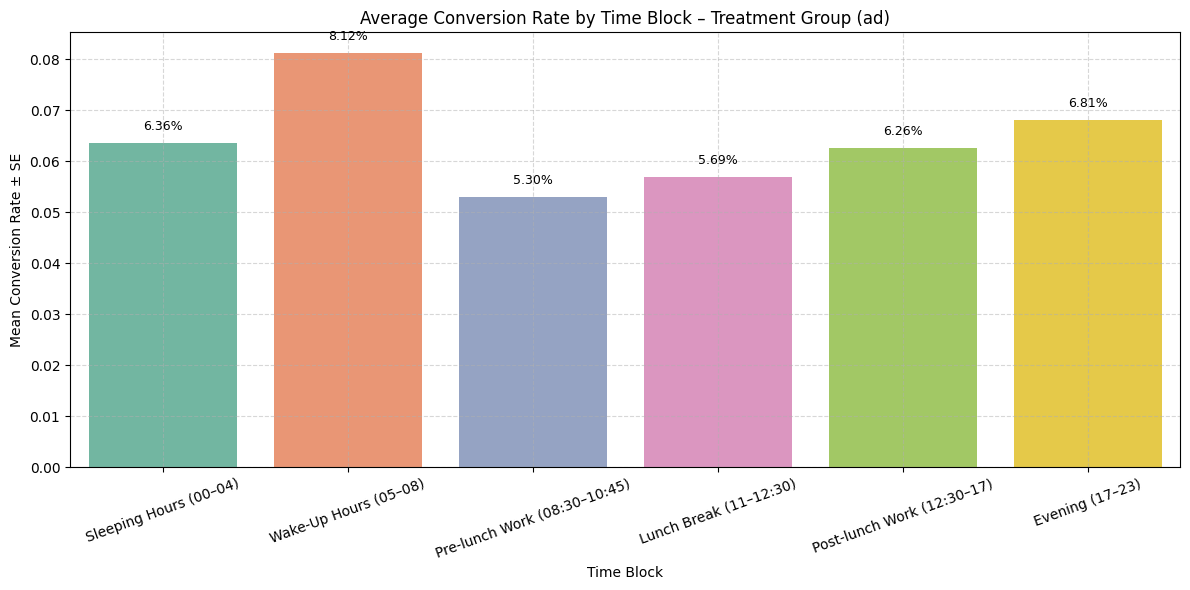

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.barplot(
    data=summary_stats,
    x='hour_block',
    y='conversion_rate',
    palette='Set2',
    errorbar='se'
)

plt.title('Average Conversion Rate by Time Block – Treatment Group (ad)')
plt.xlabel('Time Block')
plt.ylabel('Mean Conversion Rate ± SE')
plt.xticks(rotation=20)
plt.grid(True, linestyle='--', alpha=0.5)

# Add value labels above bars
for i, row in summary_stats.iterrows():
    plt.text(i, row['conversion_rate'] + 0.002, f"{row['conversion_rate']:.2%}",
             ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

The treatment group displays strong time-of-day variation in conversion performance.

Highest conversion rates occur in the early morning (05:00–08:00) and evening (18:00–23:00).
A noticeable drop is observed around lunchtime (11:00–13:00).
These insights suggest that ad delivery could be optimized by prioritizing high-performing windows and reducing spend during low-yield periods.

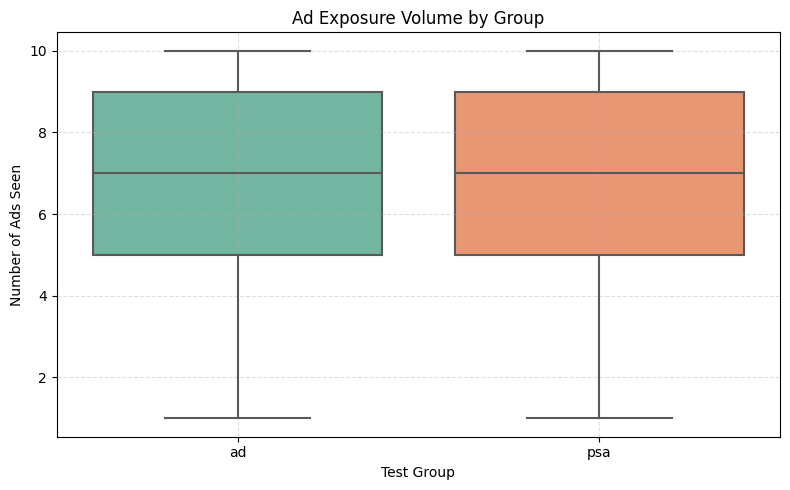

📊 Mann–Whitney U Test for ad_count between groups
U-statistic: 47623569.50
P-value: 0.4974


In [34]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# 1. Boxplot of ad_count by group
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='test group',
    y='ad_count',
    palette='Set2'
)
plt.title('Ad Exposure Volume by Group')
plt.xlabel('Test Group')
plt.ylabel('Number of Ads Seen')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# 2. Mann–Whitney U test (non-parametric)
ad_counts_ad = df[df['test group'] == 'ad']['ad_count']
ad_counts_psa = df[df['test group'] == 'psa']['ad_count']

u_stat, p_val = mannwhitneyu(ad_counts_ad, ad_counts_psa, alternative='two-sided')

# Print formatted result
print("📊 Mann–Whitney U Test for ad_count between groups")
print(f"U-statistic: {u_stat:.2f}")
print(f"P-value: {p_val:.4e}" if p_val < 0.001 else f"P-value: {p_val:.4f}")

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Version

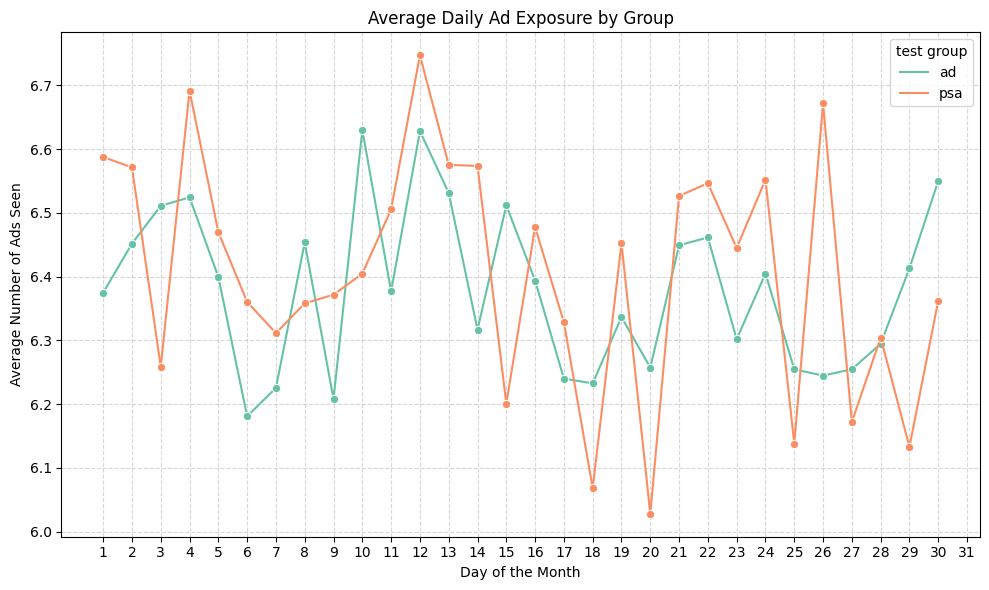

In [35]:
# 3. Daily average ad exposure per group
daily_exposure = (
    df.groupby(['days_with_most_ads', 'test group'])['ad_count']
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=daily_exposure,
    x='days_with_most_ads',
    y='ad_count',
    hue='test group',
    palette='Set2',
    marker='o'
)

plt.title('Average Daily Ad Exposure by Group')
plt.xlabel('Day of the Month')
plt.ylabel('Average Number of Ads Seen')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(1, 32))
plt.tight_layout()
plt.show()

The boxplot and Mann–Whitney U test indicate no statistically significant difference in the number of ads shown per user across the control and treatment groups (p > 0.49).

This confirms that the uplift in conversion rate is not driven by a higher ad volume, but rather by the format and design of the new ads.

The time-series plot shows consistent and balanced daily ad exposure trends across the 31-day experiment. Minor fluctuations between groups appear random and unsystematic.

Conclusion: Ad exposure was stable and evenly distributed between groups. The treatment effect is unlikely to be explained by differences in ad volume or delivery timing.


---

Launch decision:

1. there is statistically significant uplift
2. No increase in ad volume
3. Temporal consistency: conversion rates in treatment group imporved steadily
4. Behavioural insights: The highest conversion rate observed during early morning and evening hours -> points to windows for ad optimisation to increase conversion rate

Hence, there is sufficient evidence to recommend launching the new advertisement format
